In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import matplotlib.pyplot as plt 
import seaborn as sns 
import pandas as pd
import numpy as np 
import torch 
import torch.nn
sns.set()

In [3]:
from ucimlrepo import fetch_ucirepo
DryBean=fetch_ucirepo(id=602)
X=DryBean.data.features
y=DryBean.data.targets

In [4]:
X.head(10),y.head(10)

(    Area  Perimeter  MajorAxisLength  MinorAxisLength  AspectRatio  \
 0  28395    610.291       208.178117       173.888747     1.197191   
 1  28734    638.018       200.524796       182.734419     1.097356   
 2  29380    624.110       212.826130       175.931143     1.209713   
 3  30008    645.884       210.557999       182.516516     1.153638   
 4  30140    620.134       201.847882       190.279279     1.060798   
 5  30279    634.927       212.560556       181.510182     1.171067   
 6  30477    670.033       211.050155       184.039050     1.146768   
 7  30519    629.727       212.996755       182.737204     1.165591   
 8  30685    635.681       213.534145       183.157146     1.165852   
 9  30834    631.934       217.227813       180.897469     1.200834   
 
    Eccentricity  ConvexArea  EquivDiameter    Extent  Solidity  Roundness  \
 0      0.549812       28715     190.141097  0.763923  0.988856   0.958027   
 1      0.411785       29172     191.272751  0.783968  0.9849

In [5]:
X.info() , y.info()

<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
dtypes: float64(14), int64(2)
memory usage: 1.7 MB
<class 'pandas.DataFram

(None, None)

In [6]:
X.shape , y.shape

((13611, 16), (13611, 1))

In [7]:
X.isnull().sum() ,y.isnull().sum()

(Area               0
 Perimeter          0
 MajorAxisLength    0
 MinorAxisLength    0
 AspectRatio        0
 Eccentricity       0
 ConvexArea         0
 EquivDiameter      0
 Extent             0
 Solidity           0
 Roundness          0
 Compactness        0
 ShapeFactor1       0
 ShapeFactor2       0
 ShapeFactor3       0
 ShapeFactor4       0
 dtype: int64,
 Class    0
 dtype: int64)

In [8]:
Empty=y.apply(lambda val : val.astype(str).str.strip().eq("")).sum()
Empty

Class    0
dtype: int64

In [9]:
X.duplicated().sum()

np.int64(68)

In [10]:
df = pd.concat([X, y], axis=1)
df.duplicated().sum()


np.int64(68)

In [11]:
Duplicates=X.duplicated(keep=False)
print(Duplicates.sum())
X[Duplicates]

136


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
5504,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396
5505,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396
5508,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847
5509,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847
5547,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7285,63948,996.497,412.297178,198.877557,2.073121,0.875971,64641,285.343867,0.777909,0.989279,0.809254,0.692083,0.006447,0.000912,0.478979,0.992981
7339,65766,1035.842,406.416622,207.242369,1.961069,0.860218,66698,289.371512,0.792295,0.986027,0.770237,0.712007,0.006180,0.000980,0.506954,0.994172
7340,65766,1035.842,406.416622,207.242369,1.961069,0.860218,66698,289.371512,0.792295,0.986027,0.770237,0.712007,0.006180,0.000980,0.506954,0.994172
7341,65781,1039.257,409.713859,204.992832,1.998674,0.865834,66762,289.404510,0.642549,0.985306,0.765358,0.706358,0.006228,0.000956,0.498941,0.997221


In [12]:
TargetDistribution=y['Class'].value_counts(normalize=True)*100
y["Class"].unique(),y.value_counts(),TargetDistribution


(<StringArray>
 ['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']
 Length: 7, dtype: str,
 Class   
 DERMASON    3546
 SIRA        2636
 SEKER       2027
 HOROZ       1928
 CALI        1630
 BARBUNYA    1322
 BOMBAY       522
 Name: count, dtype: int64,
 Class
 DERMASON    26.052458
 SIRA        19.366689
 SEKER       14.892366
 HOROZ       14.165014
 CALI        11.975608
 BARBUNYA     9.712732
 BOMBAY       3.835133
 Name: proportion, dtype: float64)

Text(0, 0.5, 'Percentage')

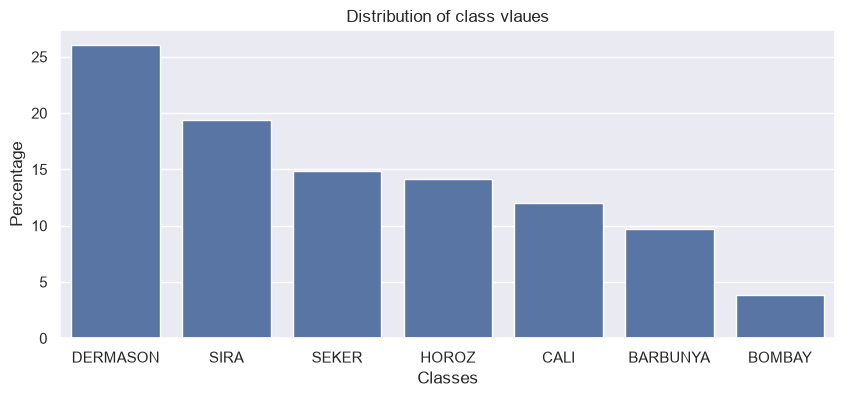

In [13]:
plt.figure(figsize=(10,4))
sns.barplot(x=TargetDistribution.index,y=TargetDistribution.values ,fill =True )
plt.title("Distribution of class vlaues")
plt.xlabel("Classes")
plt.ylabel("Percentage")

### DATASET AND TARGET DISTRIBUTION

the dataset contains 13611 al of theme are numerical values of these rows we have 68 duplicate values with zero missing values 

the target  is the classe feature which is a categorical feature which have 7 unique values which are ['SEKER', 'BARBUNYA', 'BOMBAY', 'CALI', 'HOROZ', 'SIRA', 'DERMASON']

as we can see from the barchart the data set is imbalanced because the target values are not represented equally  the variation of classes percentage is from 3% to 26%

### EDA

In [14]:
X.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


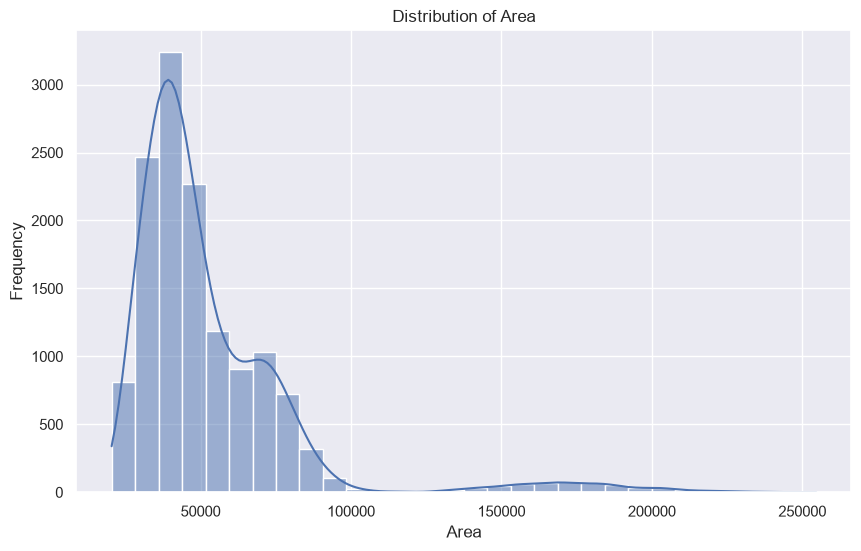

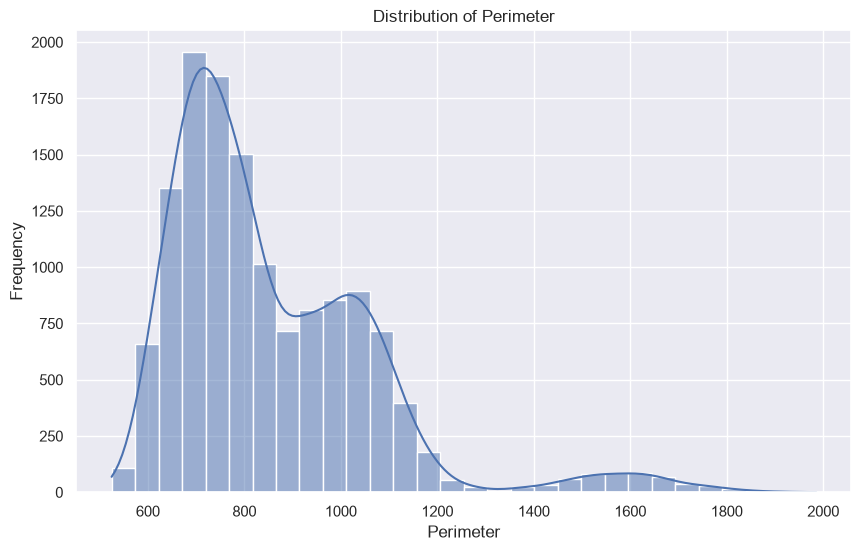

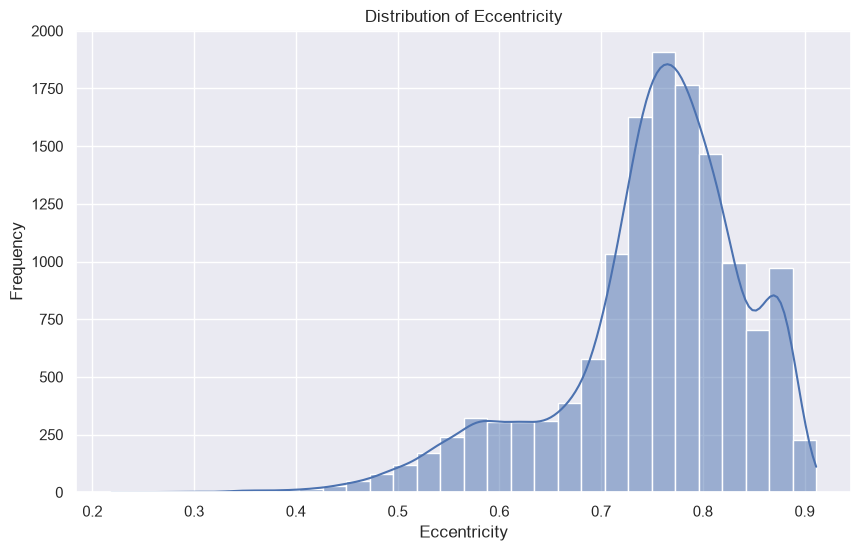

In [15]:

Features=["Area","Perimeter","Eccentricity"]

for feature in Features : 
    plt.figure(figsize=(10,6))
    sns.histplot(
        data=X,
        x=feature,
        bins=30,
        kde=True
    )
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

Area distribution : right skewedwith one peak the values with most frequency lies between 2500 and 5000 with a possible outliers of values > 250000

Perimeter distribution : also right skewed with one peak the values with most frequencey are between 600 and 1000 with possible outliers of values > 1800

Eccentricity distribution : left skewed with one peak with most frequency are between 0.7 and 0.85 

<Axes: >

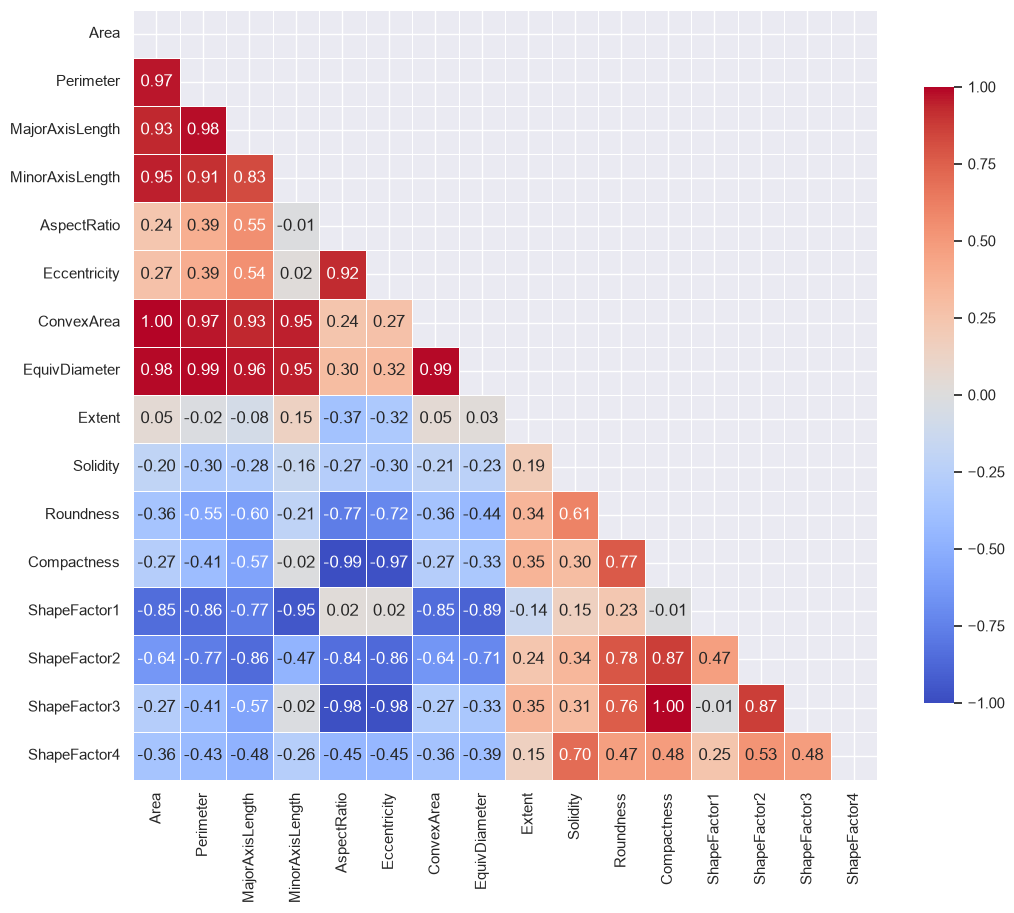

In [16]:
Correlation=X.corr()
mask = np.triu(np.ones_like(Correlation, dtype=bool))
plt.figure(figsize=(12,10))
sns.heatmap(
    Correlation,
    mask=mask,
    cmap="coolwarm",
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",linewidths=0.5,cbar_kws={"shrink": 0.8}
)

The tree most correlated pairs are (Area,Convex area) ,(shapeFactor3 , Compacteness) (concexarea , equivdiameter)

highly correlated input features illustrate the same pattern to the model to learn which means id does not provide new informations to learn which will add a workload and time conception non needed when training the model 

### EDA

In [17]:
from src.preprocessing import PrepareData

In [18]:
Xtrain,Xval,Xtest,Ytrain,Yval,Ytest,Encoder,Scaler=PrepareData(X,y,"Class")

Training means:
[ 1.06431507e-16  5.99614123e-18 -2.87814779e-16 -1.58897743e-16
  5.68134382e-16  8.78434690e-16 -1.01934401e-16 -1.10928613e-16
  4.49710592e-17  2.94860245e-15  2.53187063e-15 -9.47390314e-16
 -7.99735337e-16 -3.59768474e-17  7.79498360e-17 -6.37090006e-16]
Training standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [19]:
Xtrain.shape,Ytrain.shape , Xval.shape,Yval.shape,Xtest.shape,Ytest.shape

((9480, 16), (9480,), (2031, 16), (2031,), (2032, 16), (2032,))

### PYTORCH DATA HANDLING

In [20]:
from src.dataset import BeanDataset ,BeanLoader


In [21]:
TrainDataset=BeanDataset(Xtrain,Ytrain)
ValDataset=BeanDataset(Xval,Yval)
TestDataset=BeanDataset(Xtest,Ytest)

In [22]:
TrainLoader=BeanLoader(TrainDataset , Shuf=True)
ValLoader=BeanLoader(ValDataset)
TestLoader=BeanLoader(TestDataset )

### MODEL INITIATING

In [23]:
device="cuda" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [24]:
from src.model import BeanClassifier

model=BeanClassifier(16,[64,32],7).to(device)


In [25]:
model

BeanClassifier(
  (last): Sequential(
    (0): Linear(in_features=16, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
  )
  (classifier): Linear(in_features=32, out_features=7, bias=True)
)

### MODEL TRAINING

In [27]:
from src.train import train

In [ ]:
model=BeanClassifier(16,[64,32],7).to(device)
History , Checkpoint=train(model,TrainLoader , ValLoader , device)

epoch number5 | Trainloss=0.34  | valloss=0.24 | train f1 = 0.90 | val f1 = 0.93 
epoch number10 | Trainloss=0.31  | valloss=0.23 | train f1 = 0.90 | val f1 = 0.93 
epoch number15 | Trainloss=0.29  | valloss=0.22 | train f1 = 0.91 | val f1 = 0.93 
epoch number20 | Trainloss=0.28  | valloss=0.22 | train f1 = 0.92 | val f1 = 0.93 
epoch number25 | Trainloss=0.27  | valloss=0.22 | train f1 = 0.92 | val f1 = 0.94 
epoch number30 | Trainloss=0.28  | valloss=0.22 | train f1 = 0.92 | val f1 = 0.93 
early stopinch triggered on epoch 30 with a score of  0.9425938725471497


In [34]:
print("Best epoch:", Checkpoint["epoch"])
print("Best validation F1:", Checkpoint["best_val_F1"])

Best epoch: 21
Best validation F1: 0.9425938725471497


Text(0, 0.5, 'Loss')

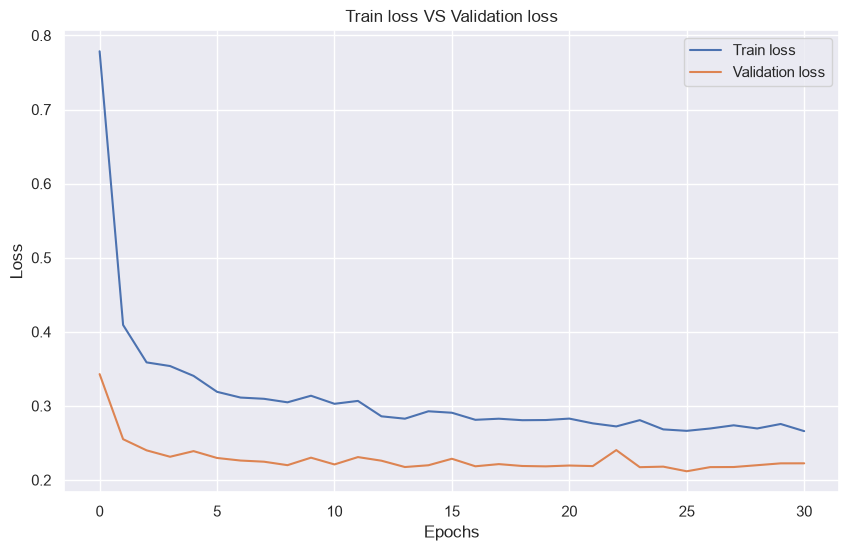

In [33]:
plt.figure(figsize=(10,6))
plt.plot(History["train_loss"],label="Train loss")
plt.plot(History["val_loss"],label="Validation loss")
plt.legend()
plt.title("Train loss VS Validation loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")


Text(0, 0.5, 'F1 score')

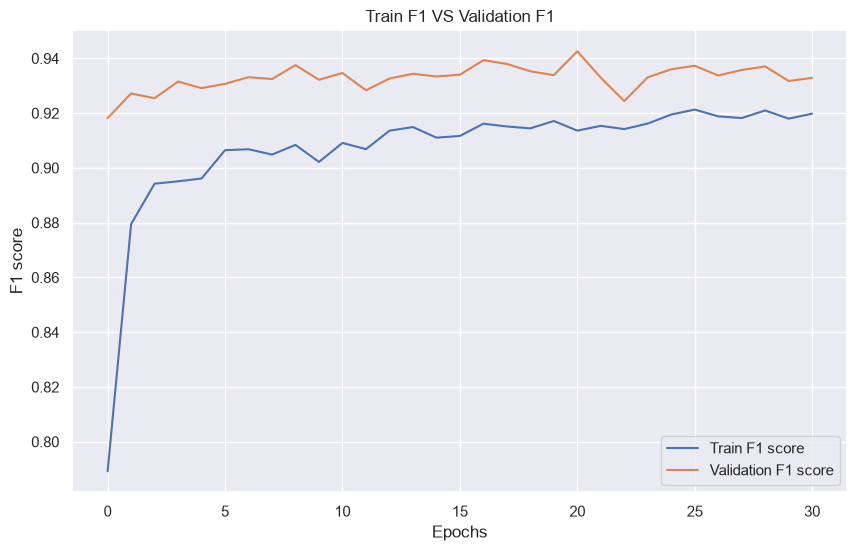

In [36]:
plt.figure(figsize=(10,6))
plt.plot(History["train_f1"],label="Train F1 score")
plt.plot(History["val_f1"],label="Validation F1 score")
plt.legend()
plt.title("Train F1 VS Validation F1")
plt.xlabel("Epochs")
plt.ylabel("F1 score")

The training and validation metrics show convergence, with moderate fluctuations throughout training. The validation macro F1-score reaches its highest value at epoch 21, after which no further improvement is observed for ten epochs. The curves do not show clear evidence of severe overfitting. Final generalization performance will be assessed using the independent test set.